# 02 · A SAXS detector image from MD atomic positions

This notebook takes a periodic molecular-dynamics box, reads it from a **LAMMPS dump**, and renders what a transmission SAXS detector would see with `midas_saxs.simulate_frame(atoms=...)`. The scattering comes from the atoms themselves: `A(G) = Σ f(|G|) exp(iG·r)` at the box's reciprocal-lattice points, shown on the detector at a stated resolution.

**Status: provisional.** The code reproduces an independent exact sum over the atoms to about 1e-9, and its absolute scale for uncorrelated disorder agrees with the exact result at about ±1 %. **A relaxed vacancy Frank loop in Cu was compared with the continuum loop amplitude (one potential, one radius, 0 K): the registered test returned REFUTED**, because the continuum's exact zero along the loop normal is not reproduced by the relaxed atoms (see the last section). Nothing here has been compared with a measured frame, and the frame treats MD boxes as independent copies of each other (no defect-defect correlations). The README section *Scattering from MD atomic positions* lists what was and was not checked.

**No LAMMPS is needed to run this notebook.** The box is a synthetic Cu crystal with a void, written to a dump file and read back, so you can see the I/O. Replace section 1 with your own dump (section 6).

**Install:** `pip install "midas-saxs>=0.2" matplotlib`

**Units:** positions and cells in Å; `q` in Å⁻¹; intensity in electrons² per Å³ of sample (times `sample_volume_A3`).

In [1]:
import math
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import midas_saxs
from midas_hkls.form_factors import form_factor
from midas_saxs import (AtomicFrame, SAXSGeometry, azimuthal_profile, read_lammps_trajectory,
                        simulate_frame, write_lammps_dump)
from midas_saxs.atomistic import atomistic_intensity, default_resolution_fwhm_inv_A, reciprocal_basis

torch.set_default_dtype(torch.float64)
print("midas_saxs", midas_saxs.__version__, " threads", torch.get_num_threads())

midas_saxs 0.1.2  threads 8


## 1 · A box, written as a LAMMPS dump and read back

FCC copper, 44 × 44 × 44 cells (159 Å, about 340,000 atoms), with a spherical void of radius 15 Å cut out. Four "frames" differ by independent 0.05 Å displacements, standing in for four snapshots of a thermal trajectory. (Real MD frames are correlated in time; that changes how many you need, not how they are combined.)

In [2]:
A_CU = 3.615
FCC = np.array([[0, 0, 0], [.5, .5, 0], [.5, 0, .5], [0, .5, .5]])


def cu_void_box(n_cells, radius_A, *, aspect=1.0, centre_frac=(0.37, 0.21, 0.11), shake=0.0, seed=0):
    # FCC Cu, n_cells^3, with an (ellipsoidal, axis z) void of equal volume to a sphere of radius_A.
    cells = np.indices((n_cells,) * 3).reshape(3, -1).T
    pos = ((cells[:, None, :] + FCC[None]) * A_CU).reshape(-1, 3)
    L = n_cells * A_CU
    d = pos - (np.array([L / 2] * 3) + np.asarray(centre_frac) * A_CU)
    a = radius_A / aspect ** (1 / 3)
    inside = (d[:, 0] / a) ** 2 + (d[:, 1] / a) ** 2 + (d[:, 2] / (a * aspect)) ** 2 <= 1.0
    keep = pos[~inside]
    if shake:
        keep = keep + shake * np.random.default_rng(seed).standard_normal(keep.shape)
    box = AtomicFrame(positions=keep, species=np.full(len(keep), "Cu"), cell=np.diag([L] * 3), timestep=seed)
    return box, int(inside.sum())


NC = 44
frames_in = [cu_void_box(NC, 15.0, shake=0.05, seed=k)[0] for k in range(4)]
n_removed = cu_void_box(NC, 15.0)[1]

tmp = tempfile.TemporaryDirectory()                       # transient scratch: this is a demo file
dump = Path(tmp.name) / "void_cu.dump"
t0 = time.time()
write_lammps_dump(dump, frames_in, type_map={1: "Cu"})
frames = read_lammps_trajectory(dump, type_map={1: "Cu"})  # the type -> element map is REQUIRED
print(f"wrote and read {len(frames)} frames of {frames[0].n_atoms} atoms ({time.time() - t0:.1f} s)")
print("cell (A):", np.round(np.diag(frames[0].cell), 2), " removed atoms:", n_removed)

wrote and read 4 frames of 339531 atoms (4.1 s)
cell (A): [159.06 159.06 159.06]  removed atoms: 1205


## 2 · The detector frame

`simulate_frame(geom, atoms=frames)` returns the usual `Frame`, with the atomistic term in `components["atoms"]` and what the estimator did in `info["atoms"]`. The cell's x axis is the beam (change that with `atoms_options={"lab_from_sample": R}`).

Look at `warnings`: a periodic box defines intensity only on its own reciprocal lattice, so pixels below about three reciprocal-lattice spacings are **not representative**. A 159 Å box has a floor near 0.12 Å⁻¹; a bigger box lowers it.

simulate_frame: 27.2 s   method=direct  frames=4  lattice points=3118
window FWHM 0.079 1/A   q floor 0.119 1/A   40 % of unmasked pixels below it
stage times (s): {'select_lattice': 0.16, 'amplitudes': 24.88, 'window': 0.51}


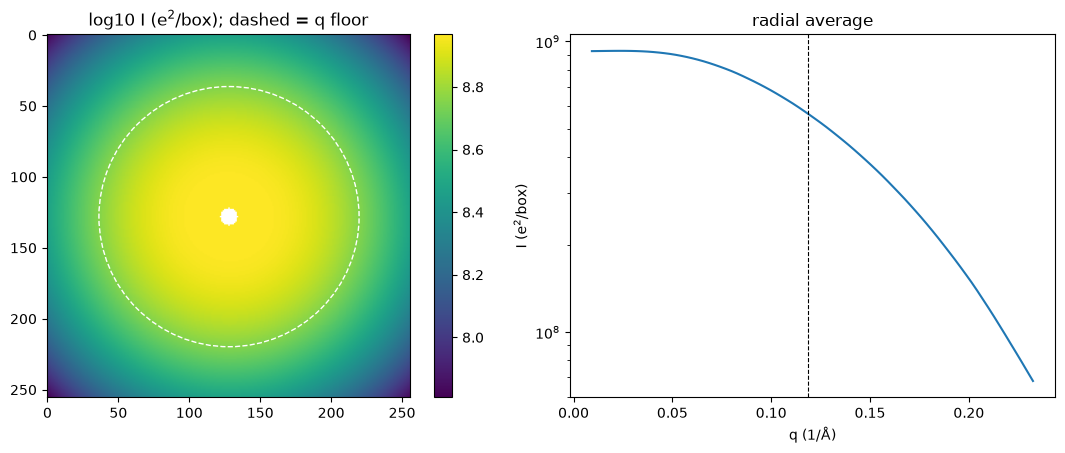

In [3]:
geom = SAXSGeometry(lsd_um=5.0e5, bcy_px=128, bcz_px=128, px_um=75.0, wavelength_A=0.7293,
                    n_pix_y=256, n_pix_z=256, beamstop_radius_px=6)
V_BOX = frames[0].volume
t0 = time.time()
fr = simulate_frame(geom, atoms=frames, sample_volume_A3=V_BOX)    # electrons^2 per box
info = fr.info["atoms"]
print(f"simulate_frame: {time.time() - t0:.1f} s   method={info['method']}  frames={info['n_frames']}  "
      f"lattice points={info['n_lattice_points']}")
print(f"window FWHM {info['resolution_fwhm_inv_A']:.3f} 1/A   q floor {info['q_floor_inv_A']:.3f} 1/A   "
      f"{100 * info['fraction_below_floor']:.0f} % of unmasked pixels below it")
print("stage times (s):", {k: round(v, 2) for k, v in info["timings_s"].items()})
for w in fr.warnings:
    print("WARNING:", w)

floor_px = info["q_floor_inv_A"] / geom.q_at_pixel_radius(1.0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
img = fr.intensity.clone()
img[~fr.mask] = float("nan")
im = ax[0].imshow(torch.log10(img.clamp_min(1e-30)).numpy(), cmap="viridis")
ax[0].add_patch(plt.Circle((geom.bcy_px, geom.bcz_px), floor_px, fill=False, ec="w", ls="--"))
ax[0].set_title("log10 I (e$^2$/box); dashed = q floor")
plt.colorbar(im, ax=ax[0])
qc, Ir, n = midas_saxs.radial_average(fr, n_bins=80)
ax[1].semilogy(qc.numpy(), Ir.numpy())
ax[1].axvline(info["q_floor_inv_A"], color="k", ls="--", lw=0.8)
ax[1].set_xlabel("q (1/Å)"); ax[1].set_ylabel("I (e$^2$/box)"); ax[1].set_title("radial average")
plt.tight_layout(); plt.show()

## 3 · Check it against an analytic curve (and how to do that fairly)

A void is the textbook SAXS object, so compare the frame with the sphere form factor of the same volume. Two things make the comparison fair:

* use the **actual removed volume** (`V_eff = N_removed · a³/4`), not `4πR³/3`: the lattice rounds the radius;
* apply **the same window average** to the analytic curve. The frame is the box's lattice-point intensities averaged with a Gaussian of stated width; comparing it with the bare analytic curve mixes a smoothing difference into the error. The helper below does that sum in plain numpy, independently of `midas_saxs.atomistic`.

(Thermal displacements add a faint diffuse background; this check uses the noiseless box so that it isolates the void.)

void: 1205 atoms removed, R_eff = 15.03 A (nominal 15)   q range 0.119-0.200 1/A
atomistic / analytic sphere (same window): mean 1.0031   max |error| 1.11 %


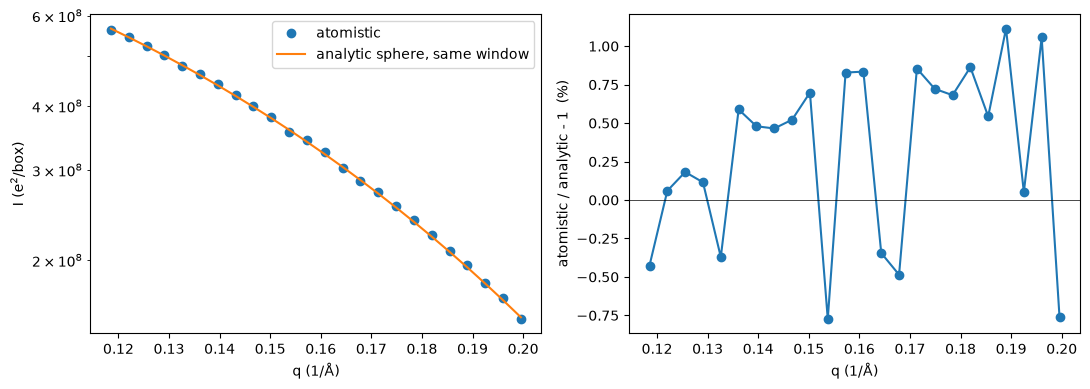

In [4]:
FW = 2 * math.sqrt(2 * math.log(2))


def window_average(q_vectors, cell, intensity_of_G, fwhm):
    # Parseval Gaussian window average of intensity_of_G(G) at each q, brute force in numpy.
    B = reciprocal_basis(cell)
    V = abs(np.linalg.det(cell))
    sig = fwhm / FW
    c = 5 * sig
    reach = int(math.ceil(c * np.linalg.norm(cell, axis=1).max() / (2 * math.pi) + 1))
    denom = (2 * math.pi * sig ** 2) ** 1.5 * V / (2 * math.pi) ** 3
    out = np.empty(len(q_vectors))
    for i, q in enumerate(q_vectors):
        h0 = np.round(q @ cell.T / (2 * math.pi)).astype(int)
        ax = [np.arange(h0[k] - reach, h0[k] + reach + 1) for k in range(3)]
        h = np.stack(np.meshgrid(*ax, indexing="ij"), axis=-1).reshape(-1, 3)
        h = h[(h != 0).any(axis=1)]
        G = h @ B
        r2 = ((G - q) ** 2).sum(axis=1)
        out[i] = ((np.exp(-r2 / (2 * sig ** 2)) * (r2 <= c * c)) * intensity_of_G(G)).sum() / denom
    return out


def F_sphere(x):
    x = np.maximum(x, 1e-12)
    return 3 * (np.sin(x) - x * np.cos(x)) / x ** 3


def f_cu(G):
    return form_factor((np.linalg.norm(G, axis=1) / (4 * math.pi)) ** 2, "Cu")


def sphere_check(radius_A, n_cells, n_points=24, seed=11):
    # Same protocol as the registered check: n_points random directions, |q| from the floor to q R_eff = 3.
    box, n_rem = cu_void_box(n_cells, radius_A)
    V_eff = n_rem / (4 / A_CU ** 3)
    R_eff = (3 * V_eff / (4 * math.pi)) ** (1 / 3)
    B = reciprocal_basis(box.cell)
    floor = 3 * float(np.linalg.norm(B, axis=1).max())
    rng = np.random.default_rng(seed)
    qmag = np.linspace(floor, 3.0 / R_eff, n_points)
    qv = rng.standard_normal((n_points, 3))
    qv = qv / np.linalg.norm(qv, axis=1)[:, None] * qmag[:, None]
    I_frame = atomistic_intensity(torch.as_tensor(qv), box)[0].numpy() * box.volume     # e^2 per box
    fwhm = default_resolution_fwhm_inv_A(box.cell)
    ref = window_average(qv, box.cell, lambda G: f_cu(G) ** 2 * n_rem ** 2 * F_sphere(np.linalg.norm(G, axis=1) * R_eff) ** 2, fwhm)
    return box, n_rem, R_eff, qmag, I_frame, ref, fwhm, qv


box, n_rem, R_eff, qs, I_frame, ref, fwhm, qv = sphere_check(15.0, NC)
err = I_frame / ref - 1
print(f"void: {n_rem} atoms removed, R_eff = {R_eff:.2f} A (nominal 15)   q range {qs.min():.3f}-{qs.max():.3f} 1/A")
print(f"atomistic / analytic sphere (same window): mean {np.mean(I_frame / ref):.4f}   max |error| {100 * np.abs(err).max():.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(qs, I_frame, "o", label="atomistic")
ax[0].semilogy(qs, ref, "-", label="analytic sphere, same window")
ax[0].set_xlabel("q (1/Å)"); ax[0].set_ylabel("I (e$^2$/box)"); ax[0].legend()
ax[1].plot(qs, 100 * err, "o-"); ax[1].axhline(0, color="k", lw=0.5)
ax[1].set_xlabel("q (1/Å)"); ax[1].set_ylabel("atomistic / analytic - 1  (%)")
plt.tight_layout(); plt.show()

The printed error is the worst of 24 q points for **this** void and **this** set of directions. In the registered checks the worst point for voids of about 1200-2000 atoms was typically 1-2 % and reached about 4 % for some void placements and direction sets, growing with q; so read the number above as "a percent or a few", not as a precise constant of the method.

## 4 · A small void: when the continuum model is the thing that is wrong

An 8 Å void is only 180 atoms. Its intensity need not follow the sphere form factor. To see whether any difference is the code or the model, compare with the **exact discrete sum** over the removed atoms (the perfect crystal contributes nothing at non-Bragg lattice points), done independently in numpy.

In [5]:
box8, n8, R8, qs8, I8, ref8, fwhm8, qv8 = sphere_check(8.0, NC)
# the removed atoms: everything in the perfect crystal that is not in the void box
cells = np.indices((NC,) * 3).reshape(3, -1).T
pos_all = ((cells[:, None, :] + FCC[None]) * A_CU).reshape(-1, 3)
d = pos_all - (np.array([NC * A_CU / 2] * 3) + np.array([0.37, 0.21, 0.11]) * A_CU)
cluster = pos_all[np.linalg.norm(d, axis=1) <= 8.0]
exact = window_average(qv8, box8.cell,
                       lambda G: f_cu(G) ** 2 * np.abs(np.exp(1j * (G @ cluster.T)).sum(axis=1)) ** 2, fwhm8)
print(f"{n8} atoms removed (R_eff {R8:.2f} A)")
print(f"atomistic / exact discrete sum : max |diff| = {np.abs(I8 / exact - 1).max():.1e}   <- the code")
print(f"atomistic / analytic sphere    : max |diff| = {100 * np.abs(I8 / ref8 - 1).max():.1f} %   <- the continuum model")

180 atoms removed (R_eff 7.98 A)
atomistic / exact discrete sum : max |diff| = 1.1e-14   <- the code
atomistic / analytic sphere    : max |diff| = 16.8 %   <- the continuum model


The first line is the code against the exact sum: rounding error. The second is the continuum model against the same atoms: in the registered checks this 180-atom void differed from the sphere by about 17 % at the worst point (other direction sets and placements gave a similar order), against about 1-2 % for the 1200-atom void above. A few hundred lattice sites are not a sphere. **This is the regime where the atomistic route is more trustworthy than a particle model**, which is the case for the sub-nanometre defects that cascades make.

## 5 · Orientation and anisotropy

Transmission SAXS has no rotation, so the sample orientation is an input. An ellipsoidal void with its long axis along z (in the detector plane, since x is the beam) scatters anisotropically; a spherical one does not. `azimuthal_profile` keeps that information, where a radial average discards it.

*Careful about what is established:* the anisotropy is real (a void's shape is in the atoms) and the code reproduces the exact sum for these atoms, but the **agreement of an ellipsoidal void with the continuum ellipsoid form factor depends on where the void sits on the lattice** and was seen to exceed 10 % for some placements. Use the atoms, not the continuum shape, when the shape matters.

sphere   : max/min over azimuth at |q| = 0.16 1/A  =  1.02
ellipsoid: max/min over azimuth at |q| = 0.16 1/A  =  7.31


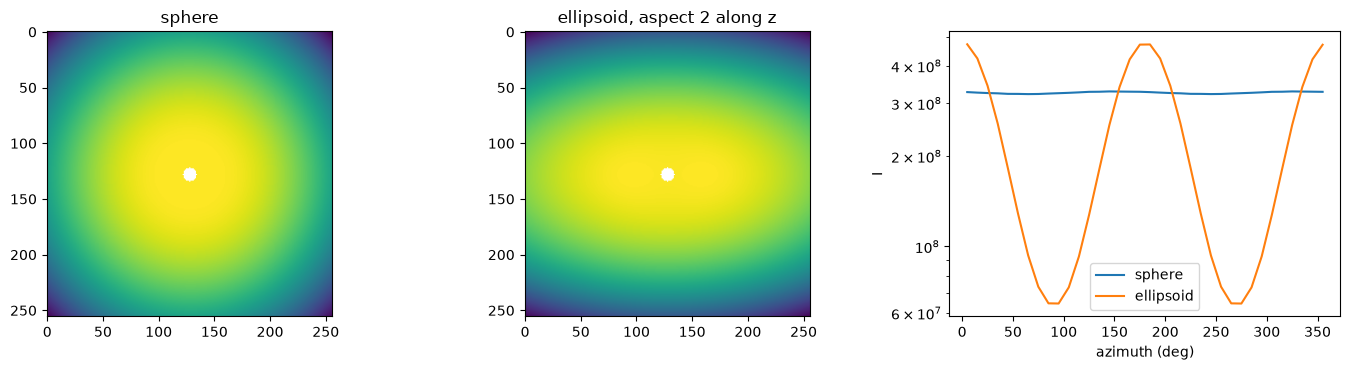

In [6]:
ell, n_ell = cu_void_box(NC, 15.0, aspect=2.0)
fr_e = simulate_frame(geom, atoms=ell, sample_volume_A3=ell.volume)
fr_s = simulate_frame(geom, atoms=cu_void_box(NC, 15.0)[0], sample_volume_A3=ell.volume)
qring = 0.16
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a_, f_, title in ((ax[0], fr_s, "sphere"), (ax[1], fr_e, "ellipsoid, aspect 2 along z")):
    im_ = f_.intensity.clone(); im_[~f_.mask] = float("nan")
    a_.imshow(torch.log10(im_.clamp_min(1e-30)).numpy(), cmap="viridis"); a_.set_title(title)
for f_, lab in ((fr_s, "sphere"), (fr_e, "ellipsoid")):
    az, I, npx = azimuthal_profile(f_, q_centre_inv_A=qring, q_width_inv_A=0.01, n_bins=36)
    ax[2].plot(az.numpy(), I.numpy(), label=lab)
    print(f"{lab:9s}: max/min over azimuth at |q| = {qring} 1/A  =  {float(I.max() / I.min()):.2f}")
ax[2].set_xlabel("azimuth (deg)"); ax[2].set_ylabel("I"); ax[2].legend(); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

## 6 · Using your own dump

```python
from midas_saxs import SAXSGeometry, simulate_frame, read_lammps_trajectory

frames = read_lammps_trajectory("my_run.dump", type_map={1: "Cu", 2: "He"},   # REQUIRED: LAMMPS types are integers
                                frames=slice(0, 200, 20))                      # fixed-cell frames only
geom = SAXSGeometry(...)                                                       # your detector
fr = simulate_frame(geom, atoms=frames, sample_volume_A3=...,
                    atoms_options={"lab_from_sample": R,                       # sample orientation, r_lab = R r_sample
                                   "resolution_fwhm_inv_A": None,              # default: two reciprocal-lattice spacings
                                   "method": "auto"})                          # or "direct" / "fft"
print(fr.warnings, fr.info["atoms"])
```

* **Units.** Dump coordinates must be in Å (LAMMPS `metal` or `real`); other unit styles are refused.
* **Fixed cell.** The frames must share the cell, atom count and species order. An NPT run changes the cell, so average only equilibrated, fixed-cell frames.
* **Check `fr.warnings` first**, in particular the q floor and, for the FFT path, the aliased-Bragg leakage bound.
* **Cost.** The direct sum costs `N_atoms × N_lattice_points` (about 2e8 pairs per second on an 8-thread laptop); the FFT path costs about `N_atoms × 216 + n³ log n` but only reaches `|h_i| ≤ n_i/8` and refuses points outside it. `info["timings_s"]` shows where the time went.
* **Orientation.** The default makes the cell's x axis the beam. For a sample with beam along `[001]` of a cubic cell, pass `lab_from_sample` as the rotation taking the cell's z axis to the lab x axis.

## What this does not do

* **Dislocation loops.** One relaxed vacancy Frank loop construction (Cu, EAM, 2 nm, 0 K) was compared with the continuum Ehrhart-Trinkaus-Larson amplitude. In plane the two agree to tens of percent (the median ratio of the atoms to an isotropic continuum is 1.13), but the continuum's exact null along the loop normal is **not** reproduced: the relaxed atoms keep a small residual that becomes the brightest direction of the ring above q R of about 3.5. Other radii, interstitial loops, other potentials and finite temperature are untested, so treat the atomistic frame of a loop as a hypothesis to check, not as a replacement for the dislocation source term (`midas_ddd`).
* **Defect-defect correlations.** The frame is the intensity of one box, scaled to the sample volume as if the boxes were independent. A dense cascade or a dislocation forest has correlations between its defects (an S(q)) that are not here.
* **Measured data.** No comparison with a measured frame, with an ExaDiS frame of the same defects, or with a resolution function.
* **Physics beyond kinematic scattering:** neutral-atom form factors, no anomalous terms, absorption, Compton or multiple scattering.
* **Low q.** The box's own periodicity sets the floor (about `3·2π/L`). A 20 nm box does not reach the lowest part of a SAXS window.